# Traditional-model batch experiment: saved cross-validation results

Run the complete experiment first. This notebook reads saved summaries and regenerates the figure; it does not fit models. K20 scores informed model selection, so they are exploratory. Error bars show sample standard deviations across three folds.

In [1]:
import csv, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd().resolve()
if root.name == "B_Traditional_ML":
    root = root.parent
results = root / "B_Traditional_ML" / "results" / "batch_experiments"
progress = json.loads((results / "progress.json").read_text(encoding="utf-8"))
assert progress["state"] == "finished", "Complete the batch experiment before plotting."

def read_rows(stage):
    path = results / f"summary_{stage}.csv"
    if not path.exists():
        return []
    with path.open(encoding="utf-8", newline="") as stream:
        return list(csv.DictReader(stream))

screen = read_rows("screen")
complete = [r for r in screen if r["status"] == "complete"]
prior_svm = json.loads((root / "B_Traditional_ML" / "results" / "cv20" / "selection.json").read_text(encoding="utf-8"))["selected"]["mean_accuracy"]
print(f"K20 complete configurations: {len(complete)} / {len(screen)}")
print("Selected configurations:", ", ".join(progress.get("chosen", [])) or "none")

K20 complete configurations: 52 / 52
Selected configurations: xgb_sign_child1_s1, extra_leaf2_features1.0


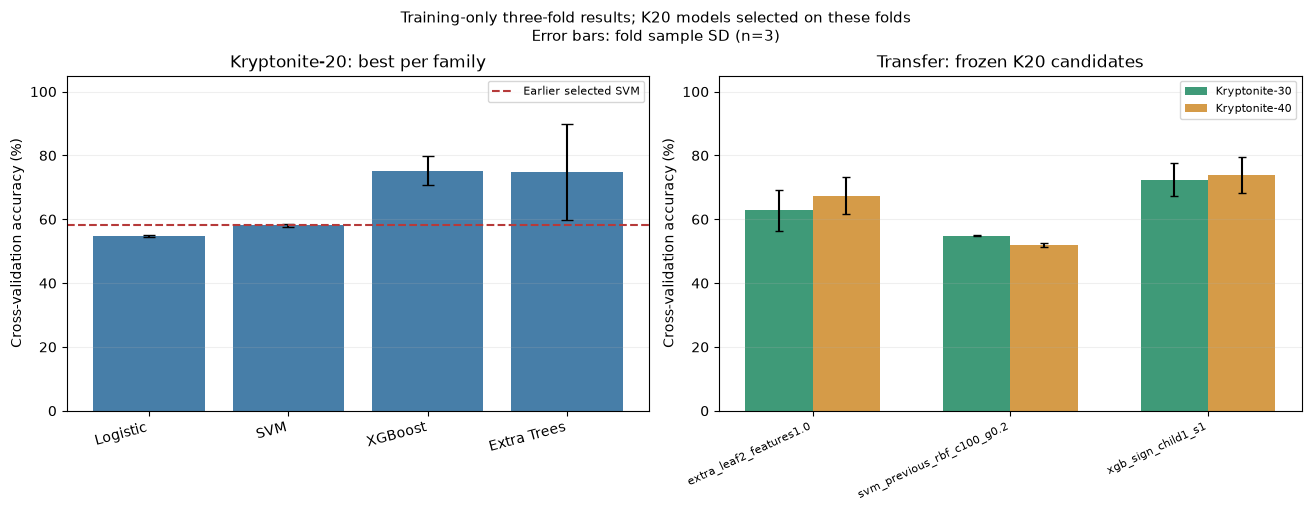

Figures saved to C:\Users\ROG\OneDrive\桌面\学习助手\Math for ML CW\B_SVM\results\batch_experiments\figures


In [2]:
families = ["logistic", "svm", "xgb", "extra"]
family_labels = {"logistic": "Logistic", "svm": "SVM", "xgb": "XGBoost", "extra": "Extra Trees"}
bests = []
for family in families:
    choices = [r for r in complete if r["family"] == family]
    if choices:
        best = max(choices, key=lambda r: (float(r["mean_accuracy"]), float(r["mean_f1"])))
        bests.append(best)

transfer = {}
for dataset in ("30", "40"):
    transfer[dataset] = {r["id"]: r for r in read_rows(dataset) if r["status"] == "complete"}
ids = sorted(set(transfer["30"]) | set(transfer["40"]))
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42})
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
ax = axes[0]
if bests:
    x = np.arange(len(bests))
    ax.bar(x, [100 * float(r["mean_accuracy"]) for r in bests],
           yerr=[100 * float(r["std_accuracy"] or 0) for r in bests], capsize=4, color="#477ea8")
    ax.set_xticks(x, [family_labels[r["family"]] for r in bests], rotation=15, ha="right")
    ax.axhline(100 * prior_svm, color="#b63a3a", linestyle="--", label="Earlier selected SVM")
    ax.legend(fontsize=8)
else:
    ax.text(.5, .5, "No complete configurations", ha="center", transform=ax.transAxes)
ax.set(title="Kryptonite-20: best per family", ylabel="Cross-validation accuracy (%)", ylim=(0, 105))
ax.grid(axis="y", alpha=.2)
ax = axes[1]
if ids:
    positions = np.arange(len(ids))
    for offset, (dataset, color) in enumerate((("30", "#3f9a78"), ("40", "#d59b48"))):
        for i, model_id in enumerate(ids):
            row = transfer[dataset].get(model_id)
            if row is None:
                continue
            ax.bar(i + (offset - .5) * .34, 100 * float(row["mean_accuracy"]), width=.34,
                   yerr=100 * float(row["std_accuracy"] or 0), capsize=3, color=color,
                   label=f"Kryptonite-{dataset}" if i == next(j for j, k in enumerate(ids) if k in transfer[dataset]) else None)
    ax.set_xticks(positions, ids, rotation=25, ha="right", fontsize=8)
    ax.legend(fontsize=8)
else:
    ax.text(.5, .5, "No complete transfer configurations", ha="center", transform=ax.transAxes)
ax.set(title="Transfer: frozen K20 candidates", ylabel="Cross-validation accuracy (%)", ylim=(0, 105))
ax.grid(axis="y", alpha=.2)
fig.suptitle("Training-only three-fold results; K20 models selected on these folds\nError bars: fold sample SD (n=3)", fontsize=11)
figure_dir = results / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_dir / "batch_accuracy.png", dpi=180)
fig.savefig(figure_dir / "batch_accuracy.pdf")
plt.show()
print("Figures saved to", figure_dir)